In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
import warnings

from scipy.stats import loguniform
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold, learning_curve
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, mean_absolute_percentage_error

warnings.filterwarnings("ignore")

## 1.1. Definición de Funciones Auxiliares de Evaluación y Diagnóstico

Para disminuir la cantidad de codigo ya que puede ser repetitivo en algunas situaciones, se tomo la decision de crear tres funciones reutilizables:

1. **imprimir_metricas(y_train, pred_train, y_test, pred_test)**: Calcula e imprime el desempeño del modelo comparando el conjunto de entrenamiento frente al de prueba mediante cuatro metricas de error:
   * **RMSE (*Root Mean Squared Error*)**: Raiz del error cuadrático medio; penaliza fuertemente los errores grandes y es la metrica principal ya que usa el mismo tipo de unidad que la variable objetivo (el mse no esta en la misma unidad por lo que no se usa).
   * **MAE (*Mean Absolute Error*)**: Promedio del error absoluto; proporciona una medida del fallo medio, esta en la misma unidad de la variable objetivo y no penaliza fuertemente los errores grandes (al contario del rmse/mae).
   * **MAPE (*Mean Absolute Percentage Error*)**: Error porcentual absoluto medio (multiplicado por 100); se usa para cuantificar el peso relativo del error, asi es mas facil apreciar que tanto se aleja del valor real el error.
   * **$R^2$ (*Coeficiente de Determinación*)**: Proporcion de la varianza de la variable objetivo que puede ser explicada por el modelo (de 0 a 1).

2. **graficar_curva_aprendizaje(estimador, X, y, ax, titulo, cv=5, n_jobs=-1)**: Evalúa el comportamiento del error del train y de la validacioon a medida que se aumenta el tamaño muestral del entrenamiento, se usa para detectar si hay overfitting, underfitting o si el modelo es "perfecto".
   * **Hiperparámetros de learning_curve**:
     * estimator=estimador: Objeto del modelo de regresión a evaluar.
     * cv=5: Cantidad de particiones que se divide el entrenamiento para realizar una validacion (la predeterminada es 5).
     * train_sizes=np.linspace(0.1, 1.0, 20): Divide en 20 trozos la particion del dataset dedicada al train, se fraciona de manera uniforme desde el 10% (0.1) hasta el 100% (1.0) de los datos de entrenamiento.
     * n_jonbs=-1: Cantidad de nucleos se usan (default="none"), al ponerlo en "-1" hace que todos los nucleos de la cpu se usen, reduciendo el tiempo de computo
     * scoring="neg_root_mean_squared_error": Define el RMSE negativo como metrica de evalluacion para el modelo de learning curve.

3. **plot_residuos(y_true, y_pred, titulo)**: Calcula los residuo y genera 5 graficos junto con dos pruebas de normalidad para ver si los residuos siguen una distribucion normal.

In [2]:
#Definimos funciones para usarlas sin tener que repetir codigo en cada celda
def imprimir_metricas(y_train, pred_train, y_test, pred_test):
    mape_train = mean_absolute_percentage_error(y_train, pred_train) * 100
    mape_test = mean_absolute_percentage_error(y_test, pred_test) * 100
    
    print(f"Train: RMSE = {root_mean_squared_error(y_train, pred_train):.2f} | MAE = {mean_absolute_error(y_train, pred_train):.2f} | MAPE = {mape_train:.2f}% | R² = {r2_score(y_train, pred_train):.3f}")
    print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | MAE = {mean_absolute_error(y_test, pred_test):.2f} | MAPE = {mape_test:.2f}% | R² = {r2_score(y_test, pred_test):.3f}")

def graficar_curva_aprendizaje(estimador, X, y, ax, titulo, cv=5, n_jobs=-1):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=estimador, 
        X=X, 
        y=y, 
        cv=cv, 
        n_jobs=n_jobs,
        train_sizes=np.linspace(0.1, 1.0, 20), # 20 puntos de evaluación
        scoring="neg_root_mean_squared_error",
        random_state=42
    )
    
    # Invertir el signo ya que scikit-learn devuelve errores negativos
    train_scores_mean = -train_scores.mean(axis=1)
    val_scores_mean = -val_scores.mean(axis=1)
    
    # Graficos
    ax.plot(train_sizes, train_scores_mean, "r-+", linewidth=2, label="train")
    ax.plot(train_sizes, val_scores_mean, "b-", linewidth=3, label="Validación (CV)")
    ax.legend(loc="upper right", fontsize=10)
    ax.set_xlabel("Tamaño del conjunto de entrenamiento")
    ax.set_ylabel("RMSE")
    ax.set_title(titulo)
    

def plot_residuos(y_true, y_pred, titulo):
    # se calculan los residuos
    residuos = y_true - y_pred

    # creacion de la figura y los subplots
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(titulo, fontsize=16, fontweight="bold")

    # grafico de dispersion
    axes[0, 0].scatter(y_true, y_pred, alpha=0.4, color="royalblue", edgecolor="w")
    axes[0, 0].plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--", lw=2)
    axes[0, 0].set_title("1. Valores Reales vs Predichos")

    # grafico de homocedasticidad
    axes[0, 1].scatter(y_pred, residuos, alpha=0.4, color="seagreen", edgecolor="w")
    axes[0, 1].axhline(0, color="r", linestyle="--", lw=2)
    axes[0, 1].set_title("2. Homocedasticidad (Residuos vs Predicciones)")

    # histograma de residuos
    sns.histplot(residuos, kde=True, ax=axes[0, 2], color="purple", bins=50)
    axes[0, 2].set_title("3. Histograma de Residuos")

    # grafico Q-Q
    stats.probplot(residuos, dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title("4. Gráfico Q-Q (Normalidad)")
    axes[1, 0].get_lines()[0].set_alpha(0.5)

    # grafico de residuos vs indice
    axes[1, 1].scatter(range(len(residuos)), residuos, alpha=0.4, color="crimson", edgecolor="w")
    axes[1, 1].axhline(0, color="black", linestyle="--", lw=2)
    axes[1, 1].set_title("5. Residuos del modelo")

    fig.delaxes(axes[1, 2])
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

    print("\n--- TESTS FORMALES DE NORMALIDAD ---")
    #  limita por si acaso el tamaño a 5000 para que el test no de error
    residuos_shapiro = np.random.choice(residuos, size=5000, replace=False) if len(residuos) > 5000 else residuos
    shapiro_stat, shapiro_p = stats.shapiro(residuos_shapiro)
    k2_stat, k2_p = stats.normaltest(residuos)

    print(f"Shapiro-Wilk: Estadístico = {shapiro_stat:.4f}, p-value = {shapiro_p:.4e}")
    print(f"D'Agostino K2: Estadístico = {k2_stat:.4f}, p-value = {k2_p:.4e}")
    print("Interpretacion: Si p-value < 0.05 rechazamos la hipotesis nula de normalidad.")

# 2. Carga de Datos

Se importa el archivo ("dataset_con_probabilidades_2.xlsx") el cual contiene las mismas variables del dataset original excepto que se ha limitado los datos para el ambito "negocio" y crediticias de los clientes junto con la probabilidad estimada de impago ("prob_impago") y la variable objetivo a predecir ("Prima").

In [3]:
# 1. Carga el dataset nuevo con la nueva variable de probabilidad
df = pd.read_excel("Data/dataset_con_probabilidades_2.xlsx")
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Impago,Prima,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,prob_impago
0,JKLXIQ,51,56857,102886,718,338,3,6.18,24,0.55,...,0,580.00,1,0,0,0,1,0,0,0.036523
1,4UO7DJ,46,45840,30473,689,291,1,14.28,36,0.34,...,0,431.25,1,0,0,0,1,0,0,0.106651
2,MO3OJW,36,48156,188824,675,161,2,13.35,36,0.55,...,0,760.00,0,0,1,0,0,1,0,0.155166
3,I14TTP,42,41472,40000,582,312,1,11.83,12,0.44,...,0,385.66,0,1,0,0,0,1,0,0.101831
4,8FUIBH,60,70202,40743,652,489,2,9.27,48,0.25,...,0,535.14,1,0,0,0,0,0,1,0.033354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76505,SXTHNM,24,17942,40000,823,35,2,12.52,36,0.55,...,1,540.62,0,0,1,0,1,0,0,0.202259
76506,0U329X,54,35399,14989,709,445,1,5.93,48,0.47,...,1,164.30,0,0,1,0,0,0,1,0.027378
76507,MY63P5,28,17390,5000,744,92,3,16.12,12,0.10,...,0,26.80,0,0,1,0,1,0,0,0.250203
76508,EPB8QX,64,40369,40000,680,447,2,7.75,12,0.19,...,1,207.42,1,0,0,0,0,1,0,0.024445


**Análisis del conjunto de datos cargado:**
* El dataset consta de 76.510 filas y 24 columnas

# 3. Exploración Inicial (EDA) y Limpieza Estructural

Se genera un nuevo dataframe (df_sin_id) excluyendo la variable "ID". Al ser una clave única de texto por póliza no aporta información estadística ni permite calcular correlaciones numéricas.

In [4]:
# Crea un nuevo dataframe a aprtir del arnterior eliminando la columna id
df_sin_id = df.drop(columns=["ID"])

## 3.1. Analisis de distribuciones (histogramas) y correlacion lineal (heatmap)

En esta celda se realiza el diagnóstico visual univariante y bivariante de las 23 variables numéricas:
* **Parametros de df_sin_id.hist**:
  * bins=20: Agrupa el rango de cada variable en 20 barras de frecuencia para detectar asimetrías (skewness), topes de censura y diferencias de escala.
* **Parametros de sns.heatmap**:
  * corr = df_sin_id.corr(): Calcula la correlacion de las variables.
  * mask=mascara: El proposito es evitar la generacion del triangulo superior del grafico, ayudando a el rendimiento y para facilitar la lectura.
  * cmap="coolwarm", vmin=-1, vmax=1: Fija la paleta desde azul oscuro este siendo correlación negativa perfecta, -1, hasta rojo oscuro, significando correlación positiva perfecta +1.

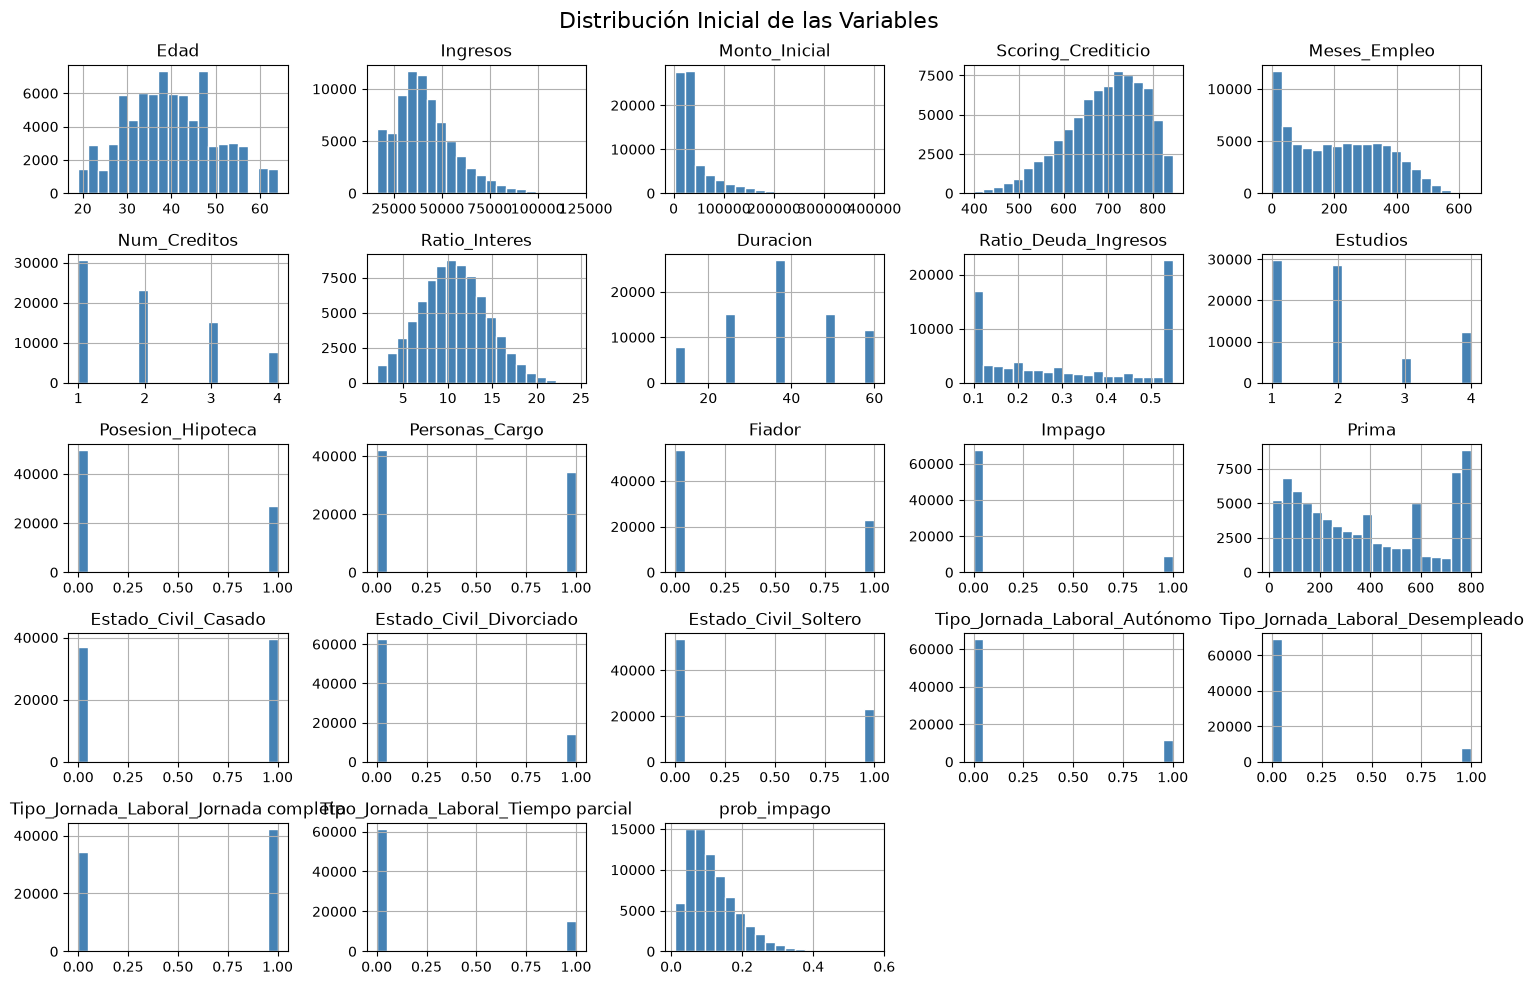

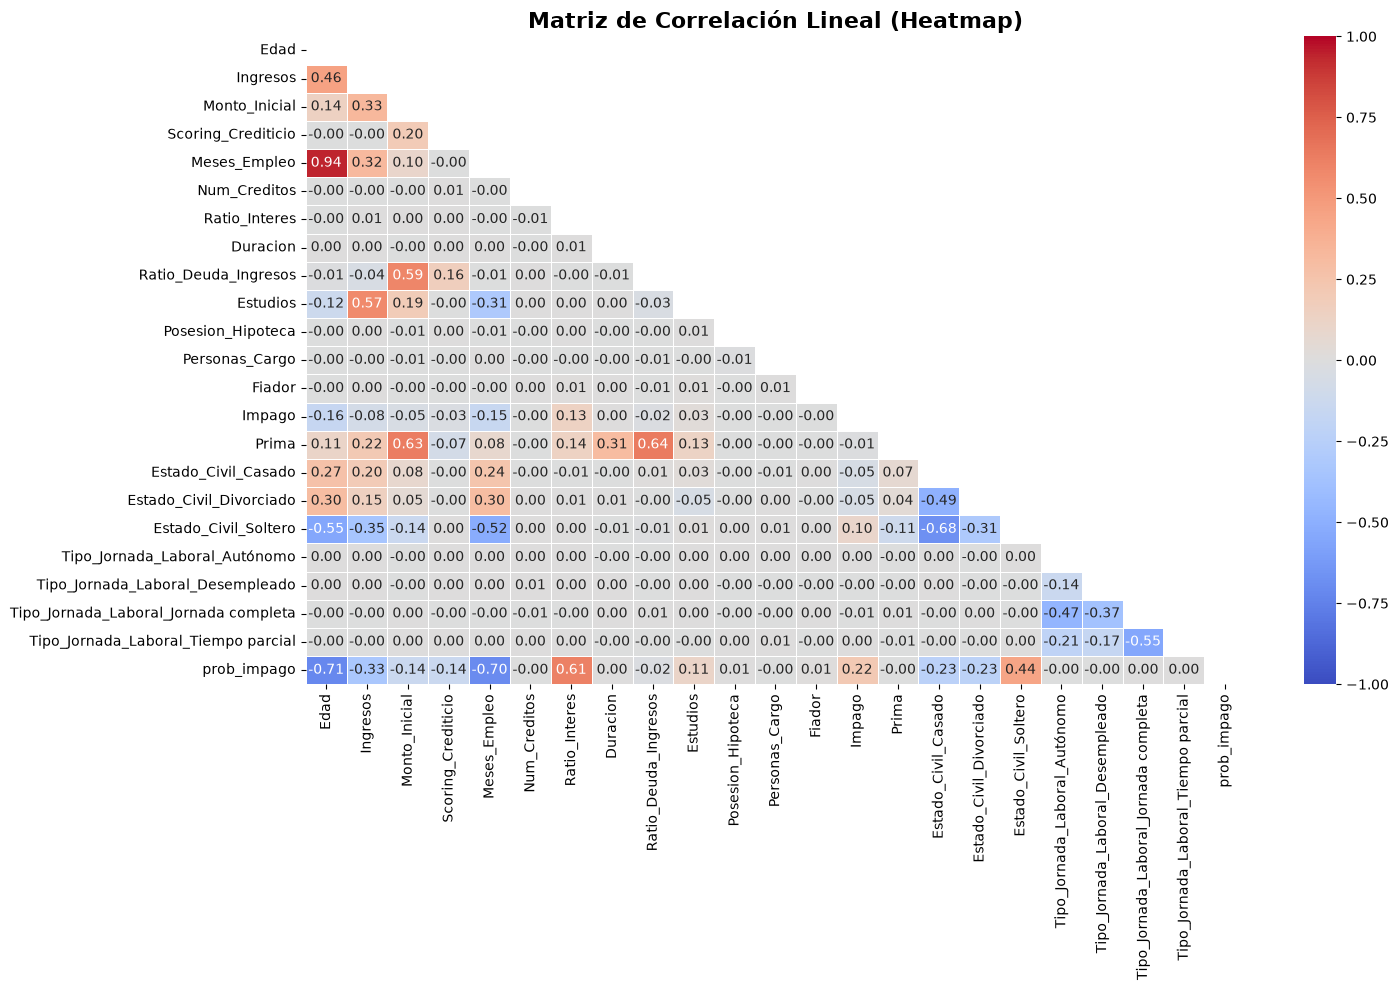

In [5]:
# 1. Histogramas de todas las variables para detectar asimetrias
df_sin_id.hist(bins=20, figsize=(15, 10), color="steelblue", edgecolor="white")
plt.suptitle("Distribución Inicial de las Variables", fontsize=16)
plt.tight_layout()
plt.show()

# 2. Matriz de Correlacion
corr = df_sin_id.corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(15, 10))
sns.heatmap(corr, annot=True,mask=mascara, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f",linewidths=0.5)
plt.title("Matriz de Correlación Lineal (Heatmap)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [6]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Estudios', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'prob_impago'],
      dtype='str')

# 4. Modelo base (OLS) para seleccion de variables

Con el objetivo de determinar cuales son las variables significativas para futuros modelo sobre la Prima, se crea un modelo de regresion lineal multiple.

**Decisiones metodológicas e hiperparámetros aplicados:**
1. **Prevención de la Trampa de Variables Ficticias**: En la lista "variables_todas" se excluye "Impago" ya que esta variable ya se ve representada por "prob_impago", ademas tambien se eliminara una variable dummy.
2. **Train test split**:Se reailza un train test split para no sobreestimar el modelo por usar todo el dataset, ya que a pesar de ser provisional es necesario aplicar este paso.

In [7]:
# Creamos la lista de variables
variables_todas = [
    "Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio",
    "Meses_Empleo", "Num_Creditos", "Ratio_Interes", "Duracion",
    "Ratio_Deuda_Ingresos", "Estudios", "Posesion_Hipoteca",
    "Personas_Cargo", "Fiador", "Estado_Civil_Casado",
    "Estado_Civil_Divorciado", "Tipo_Jornada_Laboral_Autónomo",
    "Tipo_Jornada_Laboral_Jornada completa",
    "Tipo_Jornada_Laboral_Tiempo parcial", "prob_impago"
]

X_inicial = df_sin_id[variables_todas]
y = df_sin_id["Prima"]

# 1. Dividimos los datos antes de analizar p-valores para no sobreestimar el modelo
X_train_ols, X_test_ols, y_train, y_test = train_test_split(
    X_inicial, y, 
    train_size=0.8, 
    random_state=42, 
    shuffle=True
)

# 2. Ajustamos el modelo OLS únicamente con los datos de entrenamiento
X_train_sm = sm.add_constant(X_train_ols, prepend=True)
modelo_ols_inicial = sm.OLS(endog=y_train, exog=X_train_sm).fit()

print(modelo_ols_inicial.summary())

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                     6798.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:04:05   Log-Likelihood:            -3.9416e+05
No. Observations:               61208   AIC:                         7.884e+05
Df Residuals:                   61188   BIC:                         7.885e+05
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

**Análisis del summary del Modelo OLS Inicial:**
* **Ajuste global**: El modelo lineal base alcanza un R^2 = 0.68 y R^2 Ajustado= 0.68 con un F estadistico que nos confirma que del modelo al menos una variable es significatia, ademas gracias al R^2 entendemos que el modelo explica un 68% de la varianza de la Prima
* **Variables estadísticamente NO significativas (p-valor > 0.05)**: Se comprueba que "Edad", "Num_Creditos", "Posesion_Hipoteca", "Personas_Cargo" y "Fiador" no superan el umbral de significancia al 95% de confianza, por lo que se descartan de futuros modelos.
* **Variables estadísticamente significativas (p-valor < 0.05)**: Resultan altamente significativos los predictores: "Ingresos", "Monto_Inicial", "Scoring_Crediticio", "Meses_Empleo", "Ratio_Interes", "Duracion","Ratio_Deuda_Ingresos", "Estudios", "prob_impago" y las variables dummy de estado civil y jornada laboral.

## 4.1. Filtrado de Predictores Significativos y creacion de pairplot

En esta celda se extraen las variables cuyo p-valor en el modelo OLS fue inferior a 0.05 y ademas se consideraron significativas y se visualizan las relaciones de las variables con la variable "Prima".
Ademas se grafico el pairplot con las variables significativas determinadas anteriormente.

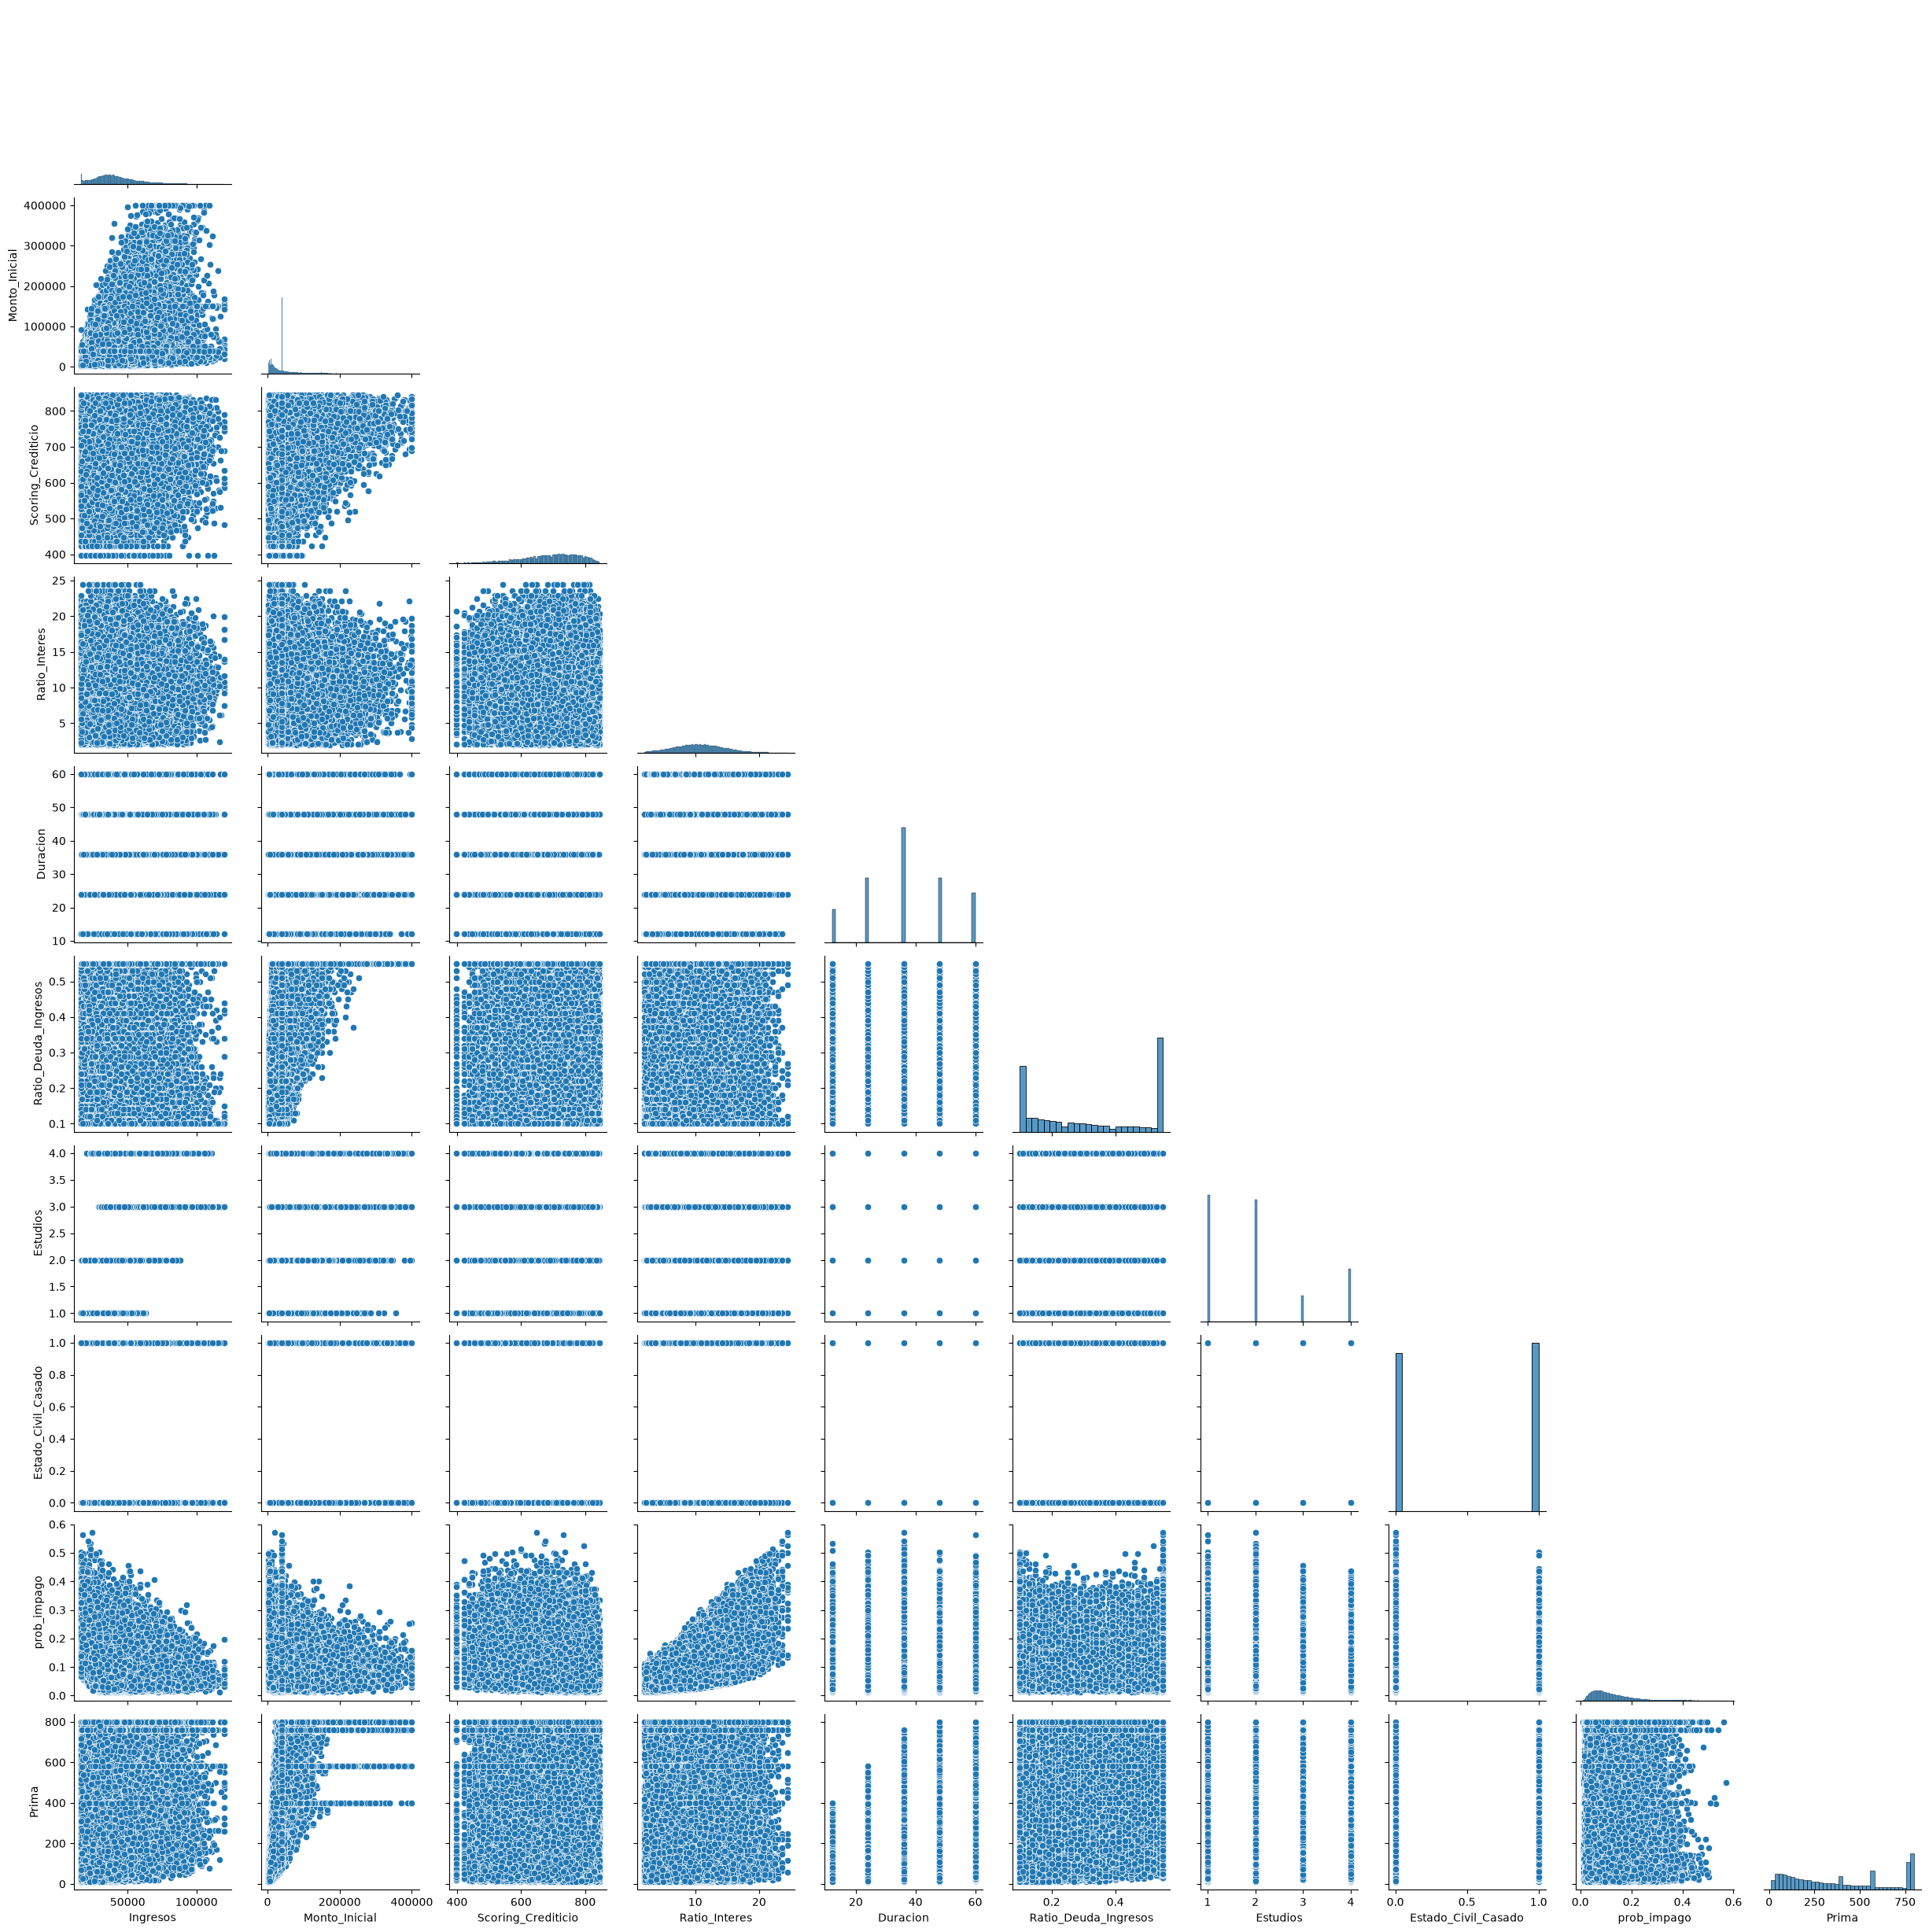

In [8]:
# Selección de Variables Significativas y Pairplot

variables_significativas = ["Ingresos", "Monto_Inicial", "Scoring_Crediticio",
    "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos", 
    "Estudios", "Estado_Civil_Casado", "prob_impago"]

variables_plot = variables_significativas + ["Prima"]
sns.pairplot(df[variables_plot],corner=True) # el corner=True evita grafifcar la diagonal la parte superior del pairplot, reduciendo el tiempo de renderizado
plt.show()

**Analisis del Pairplot y decisión de seleccion por el Principio de Parsimonia:**
* Los gráficos de dispersión frente a "Prima" confirman la existencia de curvaturas no lineales y saturación en los límites superiores de la prima.
* Decisión de Parsimonia: Aunque "Estudios", "Meses_Empleo" y las variables dummy "Estado_Civil", "Tipo_Jornada_Laboral" se determinaron significativas, no se usaran en el modelos futuros ya que no aportan tanta informacion y ya que de acuerdo al principio de parsimonia, ante modelos similares hay que elegir el mas simple y explicable, al reducir las variables conseguimos tanto eso como tambien reducir el tiempo de computo de los modelos ya que sino son muy costosos.

# 5. Preparación de los Conjuntos de Entrenamiento y Validación/Test

Se define la X con las 7 variables predictoras definitivas seleccionadas y se filtran los conjuntos de entrenamiento y test originales.

In [9]:
# 1. Selección de variables predictoras y objetivo
variables_predictoras = ["Ingresos", "Monto_Inicial", "Scoring_Crediticio",
    "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos", "prob_impago"
]

X = df[variables_predictoras]
y = df["Prima"]

# 2. División en conjunto de entrenamiento y prueba (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    train_size=0.8, 
    random_state=42, 
    shuffle=True
)

print(f"Observaciones de entrenamiento: {len(X_train)}")
print(f"Observaciones de validación/test: {len(X_test)}")

Observaciones de entrenamiento: 61208
Observaciones de validación/test: 15302


# 6. Evaluacion de grados polinomicos sin Regularizacion

Entrenamos varios modelos polinomicos de difernetes grados para ajustar el nivel de complejidad y cuanto se ajusta a los datos para ver si disminuye el error.

**Flujo de procesamiento e hiperparámetros:**
1. **PolynomialFeatures (degree=grado, include_bias=False)**:
   * degree=grado: Genera todas las potencias y productos cruzados. Se omite la columna constante mediante include_bias=False.
2. **StandardScaler()**:
   * Estandariza todas las columnas polinomicas. El modelo aprende unicamente sobre los datos de entrenamiento (.fit_transform(X_train_poly)) y se aplican sobre test (.transform(X_test_poly)) para evitar filtraciones de datos.

In [10]:
datos_por_grado = {}

for grado in [1, 2, 3, 4]:
    print("=================================================================")
    print(f" Modelo Polinómico (Sin Regularización) | Grado: {grado}")
    print("=================================================================")
    
    # Polinomios y escalado
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    nombres_poly = poly.get_feature_names_out(X_train.columns)
    
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_poly), columns=nombres_poly, index=X_train.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test_poly), columns=nombres_poly, index=X_test.index)
    
    # Entrenamiento y prediccion
    modelo_base = LinearRegression()
    modelo_base.fit(X_train_scaled, y_train)
    
    pred_train = modelo_base.predict(X_train_scaled)
    pred_test = modelo_base.predict(X_test_scaled)
    
    # Se guardan los datos para poder reutilizarlos
    datos_por_grado[grado] = {
        "X_train_scaled": X_train_scaled,
        "X_test_scaled": X_test_scaled,
        "pred_train": pred_train,
        "pred_test": pred_test,
        "num_variables": X_train_scaled.shape[1]
    }
    
    print(f"-> Variables polinómicas generadas: {X_train_scaled.shape[1]}")
    imprimir_metricas(y_train, pred_train, y_test, pred_test)

 Modelo Polinómico (Sin Regularización) | Grado: 1
-> Variables polinómicas generadas: 7
Train: RMSE = 151.83 | MAE = 120.15 | MAPE = 66.87% | R² = 0.677
Test:  RMSE = 151.15 | MAE = 119.55 | MAPE = 65.84% | R² = 0.681
 Modelo Polinómico (Sin Regularización) | Grado: 2
-> Variables polinómicas generadas: 35
Train: RMSE = 97.48 | MAE = 74.86 | MAPE = 41.16% | R² = 0.867
Test:  RMSE = 98.59 | MAE = 75.66 | MAPE = 40.65% | R² = 0.864
 Modelo Polinómico (Sin Regularización) | Grado: 3
-> Variables polinómicas generadas: 119
Train: RMSE = 75.01 | MAE = 55.83 | MAPE = 26.06% | R² = 0.921
Test:  RMSE = 75.91 | MAE = 56.36 | MAPE = 26.22% | R² = 0.920
 Modelo Polinómico (Sin Regularización) | Grado: 4
-> Variables polinómicas generadas: 329
Train: RMSE = 63.96 | MAE = 47.01 | MAPE = 20.84% | R² = 0.943
Test:  RMSE = 64.73 | MAE = 47.34 | MAPE = 20.61% | R² = 0.941


No se usara ni graficara el modelo de grado 4 ya que tiene muchas variables, es costoso, disminuye excesivamente la explicabilidad del modelo y ademas no disminuye tanto el error como para ser rentable.

**Analisis comparativo de resultados y seleccion del grado optimo:**
* **Grado 1 (7 variables)**: Obtenemos un RMSE Train = 151.83 y RMSE Test = 151.15 con un elevado MAPE Test = 65.84%. El modelo no es malisimo pero no es el idoneo.
* **Grado 2 (35 variables)**: El error cae bastante hasta RMSE Test = 98.59 y MAPE Test = 40.65% se puede apreciar que el error baja mucho aunque todavia le queda bastante como para considersarse suficientemente bajo por lo que se queda como opcion secundaria.
* **Grado 3 (119 variables)**: Logra una mejora sustancial dejando el RMSE Test = 75.91 y reduciendo el error porcentual MAPE Test = 26.22% con un R^2 > 0.92. La brecha entre entrenamiento y test es mínima 0.9 lo cual significa que el modelo no se ha sobreajustado  (cosa que puede darse al incrementar el grado).
* **Grado 4 (329 variables) y elección del Grado 3**: Aunque el Grado 4 reduce el RMSE test a 64.73, el numero de variables que genera es muy alto siendo casi el triple que en el grado anterior. A causa de esto se determina que el grado 4 no es el idoneo ya que su explicabilidad es casi nula y incrementa el tiempo de computo, por tanto, se selecciona el grado 3 como modelo ganador.

## 6.1. Diagnóstico Visual de Sesgo y Varianza: Curvas de Aprendizaje (Grados 1, 2 y 3)

Se genera una figura comparativa invocando la función "graficar_curva_aprendizaje" con un estimador "LinearRegression()" sobre los datos escalados de entrenamiento de los grados 1, 2 y 3 para visualizar la convergencia.

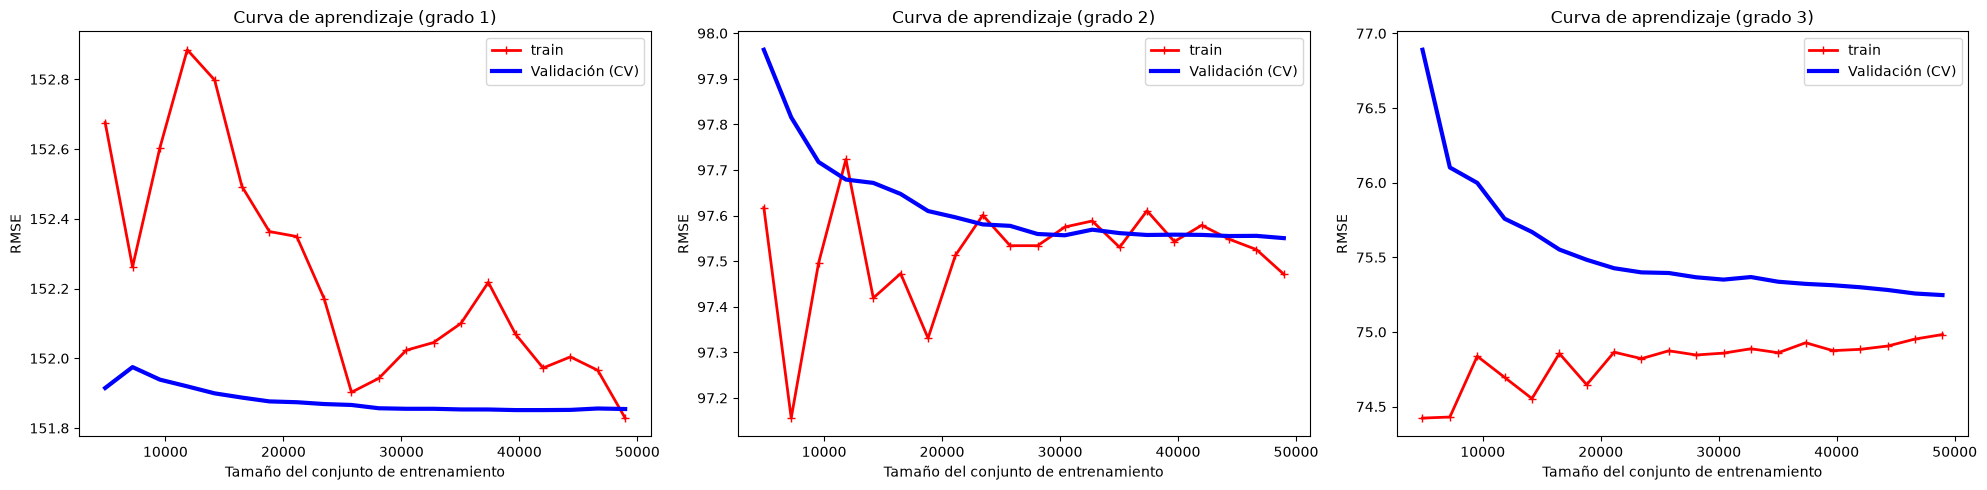

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i, grado in enumerate([1, 2, 3]):
    modelo_temp = LinearRegression()
    X_temp_train = datos_por_grado[grado]["X_train_scaled"]
    
    graficar_curva_aprendizaje(
        estimador=modelo_temp, 
        X=X_temp_train, 
        y=y_train, 
        ax=axes[i], 
        titulo=f"Curva de aprendizaje (grado {grado})"
    )

plt.tight_layout()
plt.show()

**Interpretación de las curvas de aprendizaje por grado:**
* Curva Grado 1: Las curvas de entrenamiento (roja) y validación cruzada (azul) estan dadas la vuelta (aunque no hay mucha diferencia de error), esto significa que el modelo es terrrible y que no sabe adaptarse al train, cometiendo mucho error en ambos -
* Curva Grado 2: Ambas curvas convergen rápidamente aunque de foma caotica, donde en algunos puntos el train tiene mayor rmse que el test, no es el mejor grado
* Curva Grado 3: Tras una ligera separación lógica inicial por la estimación de 119 parámetros, a medida que aumenta el tamaño de entrenamiento ambas curvas convergen de forma estable entorno a el rmse de 75, es probable que con mas datos el error podria disminuir mas. Es el mejor grado de los tres ya que no tiene ni overfitting ni underfitting

# 6.2. Residuos del Modelo Base Ganador (Grado 3 en Train)

Se ejecuta la función "plot_residuos" pasándole los valores reales y las predicciones de entrenamiento del Grado 3 (el mejor modelo), con el objetivo de verificar el comportamiento de los errores antes de regularizar.

Auditando Modelo Base (Sin Regularizar): Grado 3


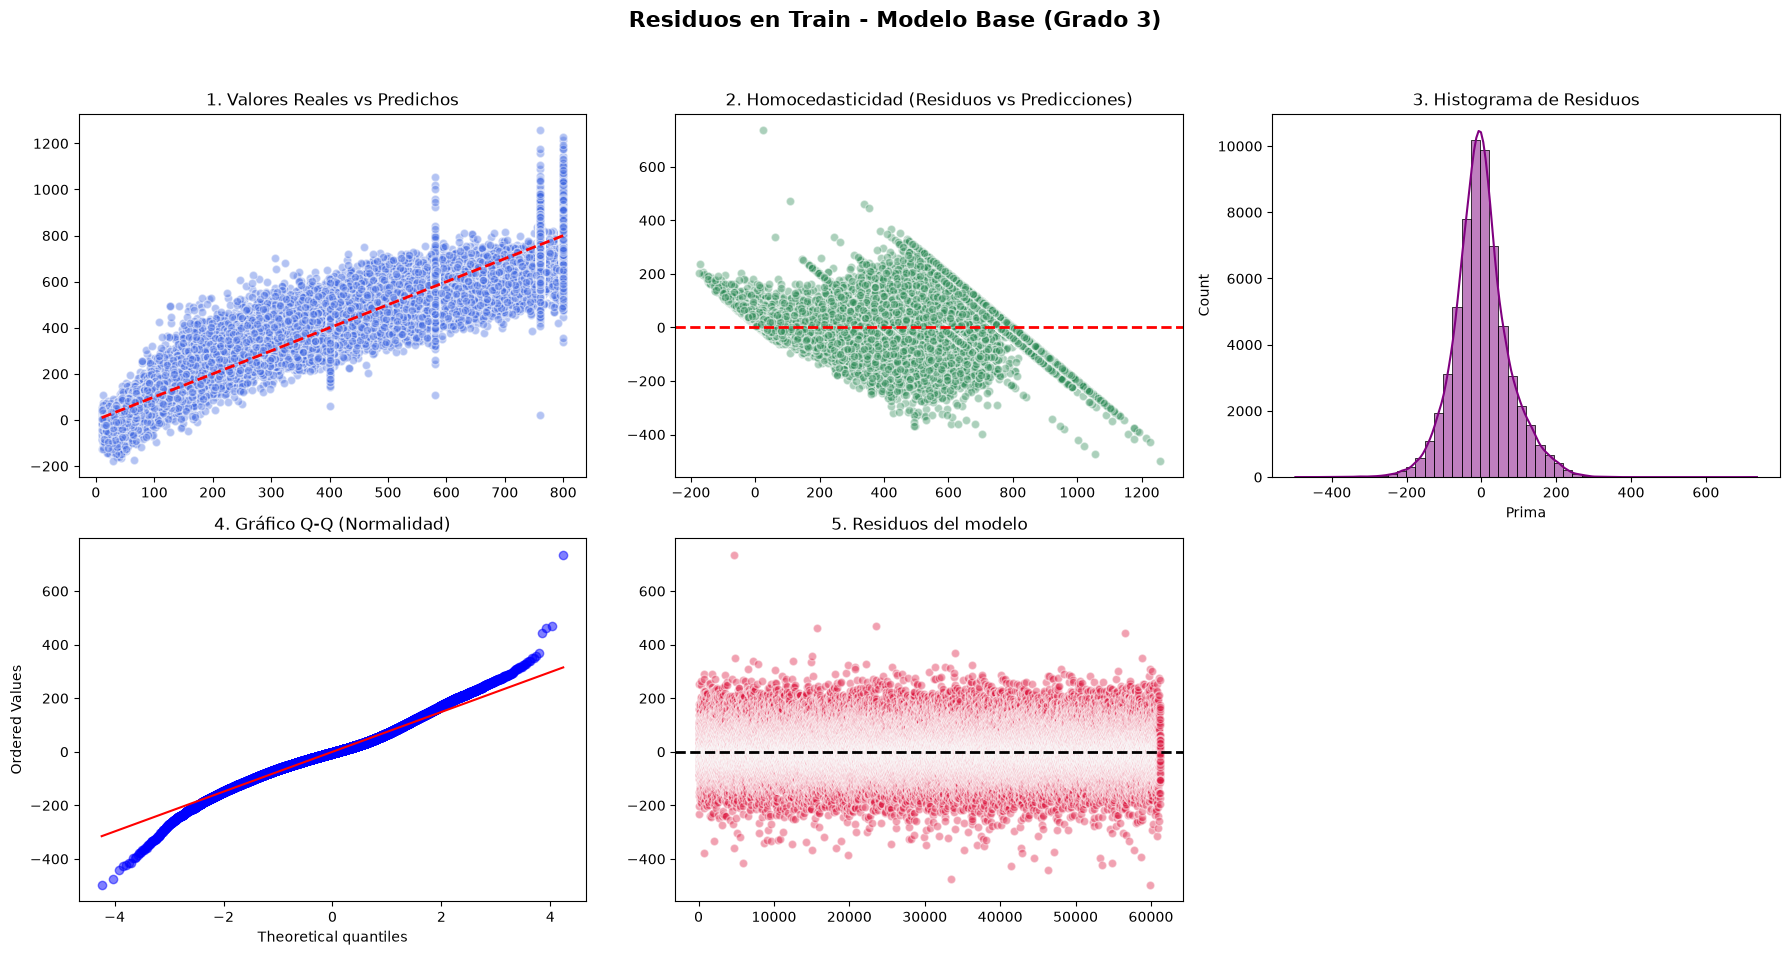


--- TESTS FORMALES DE NORMALIDAD ---
Shapiro-Wilk: Estadístico = 0.9828, p-value = 3.3202e-24
D'Agostino K2: Estadístico = 2561.0165, p-value = 0.0000e+00
Interpretacion: Si p-value < 0.05 rechazamos la hipotesis nula de normalidad.


In [12]:
# Analisis de residuos del grado ganador
grado_ganador = 3 
print(f"Auditando Modelo Base (Sin Regularizar): Grado {grado_ganador}")

pred_train_base = datos_por_grado[grado_ganador]["pred_train"]
plot_residuos(y_train, pred_train_base, f"Residuos en Train - Modelo Base (Grado {grado_ganador})")

**Diagnóstico de los residuos del Modelo Base (Grado 3):**
1. **Valores Reales vs. Predichos**: La nube se agrupa sólidamente sobre la línea roja discontinua demostrando una alta capacidad predictiva, aunque contiene varias acumulaciones en algunos puntos sobre todo en el rango 760–800 que se debe a primas fijas.
2. **Homocedasticidad (Residuos vs. Predicciones)**: Analizando ha homoeasticidad del modelo se puede confirmar que no existe ya que el error no es independiente a lo largo de todas las observaciones.
3. **Normalidad (Histograma, Q-Q Plot y Tests Estadísticos)**: El histograma genera una campana simetrica centrada exactamente en 0. Aunque los tests de Shapiro-Wilk y D'Agostino arrojen un p-valor < 0.05 ,rechazando la normalidad estricta debido a algunas colas pesadas (casi no se aprecioan).
4. **Residuos del modelo**: La banda horizontal uniforme centrada en 0 confirma que los errores son totalmente independiente (ruido blanco).

# 7. Fase 2: Regularización y seleccion aleatoria de hiperparametros (Lasso y ElasticNet)

Sobre la matriz estandarizada de Grado 3 (la cual contiene 119 variables) se considero el uso de la regularizacion Lasso y Elastic net  no con el objetivo de que el modelo sea capaz de generalizar mejor sino con el de reducir el numero de variables consiguiendo un modelo mas facil de interpretar, para conseguir los mejores hiperparametros se uso el modelo randomsearch.

**Desglose de hiperparámetros configurados:**
* **KFold(n_splits=5)**: Garantiza que tanto Lasso como ElasticNet se evaluen bajo las mismas particiones.
* **max_iter=3000`**: Numero de iteraciones (por defecto 1.000) para asegurar la convergencia al evaluar penalizaciones sobre 119 variables simultaneas (tener cuidado por que de aumentarlo mucho el tiempo de procesado aumenta mucho).
* **"alpha": loguniform(0.01, 1000)**: Muestrea el hiperparametro de penalizacian en escala logaritmica garantizando que se bueque en las mismas condiciones en cada orden de magnitud.
* **"l1_ratio": [0.25, 0.5, 0.95]**: Controla la proporcion entre L1 y L2 en ElasticNet.
* **scoring="neg_root_mean_squared_error"**: Selecciona el modelo que minimice el RMSE promedio de validacion.

In [14]:
X_train_ganador = datos_por_grado[grado_ganador]["X_train_scaled"]
X_test_ganador = datos_por_grado[grado_ganador]["X_test_scaled"]

cv_optimo = KFold(n_splits=5, shuffle=True, random_state=42)

modelos_regularizacion = {
    "Lasso (L1)": RandomizedSearchCV(
        estimator=Lasso(max_iter=3000, random_state=42), #aumentar el numero de iteraciones puede mejorar un poco el resultado pero se recomienda hacerlo debido a su alto coste computacional
        param_distributions={"alpha": loguniform(0.01, 1000)},
        n_iter=30, 
        cv=cv_optimo, 
        n_jobs=-1, #se usa n_jobs=-1 para que use todos los cores y acelerar el proceso de busqueda de hiperparametros reduciendo el tiempo de busqueda
        scoring="neg_root_mean_squared_error",
        random_state=42
    ),
    "ElasticNet (L1 + L2)": RandomizedSearchCV(
        estimator=ElasticNet(max_iter=3000, random_state=42),
        param_distributions={"alpha": loguniform(0.01, 1000),
        "l1_ratio": [0.25, 0.5, 0.95]},
        n_iter=40, 
        cv=cv_optimo, 
        n_jobs=-1,
        scoring="neg_root_mean_squared_error",
        random_state=42
    )
}

predicciones_train_reg = {}
modelos_finales = {}

for nombre_reg, search in modelos_regularizacion.items():
    print(f" Entrenando: {nombre_reg}")
    print("=================================================================")
    
    search.fit(X_train_ganador, y_train)
    mejor_modelo = search.best_estimator_
    modelos_finales[nombre_reg] = mejor_modelo
    
    vars_totales = X_train_ganador.shape[1]
    vars_cero = int(np.sum(mejor_modelo.coef_ == 0))
    
    pred_train = mejor_modelo.predict(X_train_ganador)
    pred_test = mejor_modelo.predict(X_test_ganador)
    
    predicciones_train_reg[nombre_reg] = pred_train
    
    mejores_params = search.best_params_
    print(f"-> Parámetros óptimos: {mejores_params}")
    print(f"-> Variables purgadas (coeficientes = 0): {vars_cero} de {vars_totales}")
    
    imprimir_metricas(y_train, pred_train, y_test, pred_test)
    print("")

 Entrenando: Lasso (L1)
-> Parámetros óptimos: {'alpha': np.float64(0.0195172246414495)}
-> Variables purgadas (coeficientes = 0): 6 de 119
Train: RMSE = 79.37 | MAE = 59.78 | MAPE = 28.95% | R² = 0.912
Test:  RMSE = 80.14 | MAE = 60.44 | MAPE = 29.29% | R² = 0.910

 Entrenando: ElasticNet (L1 + L2)
-> Parámetros óptimos: {'alpha': np.float64(0.017070728830306643), 'l1_ratio': 0.95}
-> Variables purgadas (coeficientes = 0): 10 de 119
Train: RMSE = 82.07 | MAE = 62.33 | MAPE = 31.02% | R² = 0.906
Test:  RMSE = 82.78 | MAE = 62.89 | MAPE = 31.04% | R² = 0.904



**Analisis de los resultados y comparacion de modelos regularizados:**
1. **Rendimiento de Lasso (L1)**:
   * **Seleccion de variables**: Anula exactamente a cero 6 de las 119 variables dejando el modelo con 108 predictores activos.
   * **Metricas de error**: RMSE Train = 79.37 y RMSE Test = 80.14, el error aumento en comparaicon a lo que tenia antes aunque no demasiado.
2. **Rendimiento de ElasticNet (L1 + L2)**:
   * **Hiperparametros aptimos**: El ratio mas cercano a Lasso puro l1_ratio = 0.95 confirmando que los datos requieren mucha más penalización L1 que L2.
   * **Seleccion de variables y métricas**: Elimino 10 de las 119 variables y el error aumento aun mas que el anterior RMSE Test = 82.78 
3. **Decisión final**: Se determino que no se utilizara el modelo regularizado ya que no merece la pena aumentar el error para las pocas variables que elimina el modelo, por lo que se usara el modelo de grado 3 original para la prediccion.

No sera necesario realizar un analisis de residuos de los modelos regularizados ya que el objetivo de la regularizacion era reduccir la dimensionalidad y al no haberlo conseguido se da por concluido ese apartado.